# Course of Dimensionality

## 1. Feature Extraction
## 2. Feature Selection

## 1.1 Principle Component Analysis(PCA)

In [2]:
import numpy as np
import pandas as pd

np.random.seed(23)

mu_vec1 = np.array([0,0,0])
cov_mat1 = np.array([[1,0,0],[0,1,0],[0,0,1]])
class1_sample = np.random.multivariate_normal(mu_vec1, cov_mat1, 20)

df = pd.DataFrame(class1_sample, columns=['feature1','feature2','feature3'])
df['target'] = 1

mu_vec2 = np.array([1,1,1])
cov_mat2 = np.array([[1,0,0],[0,1,0],[0,0,1]])
class2_sample = np.random.multivariate_normal(mu_vec2, cov_mat2, 20)

df1 = pd.DataFrame(class2_sample, columns=['feature1','feature2','feature3'])

df1['target'] = 0

df = pd.concat([df,df1],ignore_index=True)

df = df.sample(40)


In [3]:
df.head()

,feature1,feature2,feature3,target
2,-0.367548,-1.137460,-1.322148,1
34,0.177061,-0.598109,1.226512,0
14,0.420623,0.411620,-0.071324,1
11,1.968435,-0.547788,-0.679418,1
12,-2.506230,0.146960,0.606195,1


In [6]:
!pip install plotly

   ---------------------------------------- 0.0/9.7 MB ? eta -:--:--
   ---- ----------------------------------- 1.0/9.7 MB 9.2 MB/s eta 0:00:01
   ------------ --------------------------- 3.1/9.7 MB 9.8 MB/s eta 0:00:01
   ------------------ --------------------- 4.5/9.7 MB 8.6 MB/s eta 0:00:01
   ------------------------- -------------- 6.3/9.7 MB 8.6 MB/s eta 0:00:01
   ------------------------------- -------- 7.6/9.7 MB 8.0 MB/s eta 0:00:01
   ------------------------------------ --- 8.9/9.7 MB 7.7 MB/s eta 0:00:01
   -------------------------------------- - 9.4/9.7 MB 7.3 MB/s eta 0:00:01
   ---------------------------------------- 9.7/9.7 MB 6.8 MB/s  0:00:01



[notice] A new release of pip is available: 26.2.1 -> 26.2.2
[notice] To update, run: python.exe -m pip install --upgrade pip


In [11]:
!python.exe -m pip install --upgrade pip

  Using cached pip-26.2.2-py3-none-any.whl.metadata (4.6 kB)
Using cached pip-26.2.2-py3-none-any.whl (1.8 MB)
  Attempting uninstall: pip
    Found existing installation: pip 26.2.1
    Uninstalling pip-26.2.1:
      Successfully uninstalled pip-26.2.1


In [13]:
import plotly.express as px

# Convert target to string first so Plotly treats it as discrete categories (colors)
df['target'] = df['target'].astype(str)

# Pass column names as strings when using a DataFrame source
fig = px.scatter_3d(df, x='feature1', y='feature2', z='feature3', color='target')

fig.update_traces(marker=dict(size=12,
                              line=dict(width=2,
                                        color='DarkSlateGrey')),
                  selector=dict(mode='markers'))

fig.show()


In [14]:
fig.show()

In [9]:
# Step 1 - Apply standard scaling
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()
df.iloc[:, 0:3] = scaler.fit_transform(df.iloc[:, 0:3])

# Calculate covariance matrix
covariance_matrix = np.cov([df.iloc[:, 0], df.iloc[:, 1], df.iloc[:, 2]])
print('Covariance Matrix:\n', covariance_matrix)

# Calculate eigenvalues and eigenvectors
eigen_values, eigen_vectors = np.linalg.eig(covariance_matrix)

eigen_values


Covariance Matrix:
 [[1.02564103 0.20478114 0.080118  ]
 [0.20478114 1.02564103 0.19838882]
 [0.080118   0.19838882 1.02564103]]


array([1.3536065 +0.j, 0.94557084+0.j, 0.77774573+0.j])

In [15]:
eigen_vectors

array([[-0.53875915+0.j, -0.69363291+0.j,  0.47813384+0.j],
       [-0.65608325+0.j, -0.01057596+0.j, -0.75461442+0.j],
       [-0.52848211+0.j,  0.72025103+0.j,  0.44938304+0.j]])

In [16]:
%pylab inline

from matplotlib import pyplot as plt
from mpl_toolkits.mplot3d import Axes3D
from mpl_toolkits.mplot3d import proj3d
from matplotlib.patches import FancyArrowPatch

class Arrow3D(FancyArrowPatch):
    def __init__(self, xs, ys, zs, *args, **kwargs):
        FancyArrowPatch.__init__(self, (0,0), (0,0), *args, **kwargs)
        self._verts3d = xs, ys, zs

    def draw(self, renderer):
        xs3d, ys3d, zs3d = self._verts3d
        xs, ys, zs = proj3d.proj_transform(xs3d, ys3d, zs3d, renderer.M)
        self.set_positions((xs[0],ys[0]),(xs[1],ys[1]))
        FancyArrowPatch.draw(self, renderer)

fig = plt.figure(figsize=(7,7))
ax = fig.add_subplot(111, projection='3d')

ax.plot(df['feature1'], df['feature2'], df['feature3'], 'o', markersize=8, color='blue', alpha=0.2)
ax.plot([df['feature1'].mean()], [df['feature2'].mean()], [df['feature3'].mean()], 'o', markersize=10, color='red', alpha=0.5)
for v in eigen_vectors.T:
    a = Arrow3D([df['feature1'].mean(), v[0]], [df['feature2'].mean(), v[1]], [df['feature3'].mean(), v[2]], mutation_scale=20, lw=3, arrowstyle="->")
    ax.add_artist(a)
ax.set_xlabel('x_values')
ax.set_ylabel('y_values')
ax.set_zlabel('z_values')

plt.title('Eigenvectors')

plt.show()


%pylab is deprecated, use %matplotlib inline and import the required libraries.
Populating the interactive namespace from numpy and matplotlib


AttributeError: 'Arrow3D' object has no attribute 'do_3d_projection'

<Figure size 700x700 with 1 Axes>

In [17]:
import numpy as np
from matplotlib.patches import FancyArrowPatch
from mpl_toolkits.mplot3d import proj3d

class Arrow3D(FancyArrowPatch):
    def __init__(self, xs, ys, zs, *args, **kwargs):
        super().__init__((0, 0), (0, 0), *args, **kwargs)
        self._verts3d = xs, ys, zs

    def do_3d_projection(self, renderer=None):
        xs3d, ys3d, zs3d = self._verts3d
        # Transform 3D coordinates to 2D projection space
        xs, ys, zs = proj3d.proj_transform(xs3d, ys3d, zs3d, self.axes.M)
        self.set_positions((xs[0], ys[0]), (xs[1], ys[1]))
        # Return the minimum z-value for Matplotlib's depth sorting engine
        return np.min(zs)


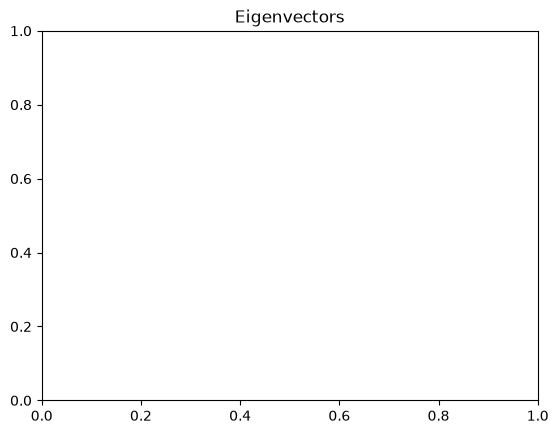

In [18]:
# Plot the mean point
ax.plot([df['feature1'].mean()], [df['feature2'].mean()], [df['feature3'].mean()], 'o', markersize=10, color='red', alpha=0.5)

# Generate the 3D arrows for eigenvectors
for v in eigen_vectors.T:
    # Adding mean to v endpoints scales and positions them outward from the center point
    a = Arrow3D([df['feature1'].mean(), df['feature1'].mean() + v[0]], 
                [df['feature2'].mean(), df['feature2'].mean() + v[1]], 
                [df['feature3'].mean(), df['feature3'].mean() + v[2]], 
                mutation_scale=20, lw=3, arrowstyle="->")
    ax.add_artist(a)

ax.set_xlabel('x_values')
ax.set_ylabel('y_values')
ax.set_zlabel('z_values')

plt.title('Eigenvectors')
plt.show()
